# Análisis Exploratorio — Infraestructura de Carga para VE

**Proyecto:** Visualización de la accesibilidad territorial de la infraestructura de carga para distintos rangos de autonomía.

**Objetivo del notebook:** Evaluar la factibilidad de cada tarea propuesta:
1. Caracterizar cantidad y capacidad de las instalaciones.
2. Explorar la distribución espacial.
3. Analizar la separación entre puntos de carga.
4. Comparar separaciones con distintos rangos de autonomía.

## 0. Imports y carga de datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy.spatial.distance import cdist
from scipy.spatial import cKDTree

# Paleta de colores consistente con el estilo del curso
MAGENTA = "#ecc47e"
AZUL    = "#3222A6"
GRIS    = "#BDBDBD"
NARANJA = "#E68200"

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

# ----- Carga -----
priv = pd.read_excel("C:\\Users\\Lenovo\\infovis\\InfoVis\\datasets\\PRIVADAS.xlsx", parse_dates=False)
pub  = pd.read_excel("C:\\Users\\Lenovo\\infovis\\InfoVis\\datasets\\PÚBLICAS.xlsx",  parse_dates=False)

# Parsear fechas manualmente (formato DD-MM-YYYY)
for df in (priv, pub):
    df["FECHA"] = pd.to_datetime(df["FECHA_INSCRIPCIÓN"], dayfirst=True, errors="coerce")
    df["AÑO"]   = df["FECHA"].dt.year

print(f"Instalaciones privadas : {len(priv):>5,}")
print(f"Instalaciones públicas : {len(pub):>5,}")
print(f"Total                  : {len(priv)+len(pub):>5,}")

Instalaciones privadas : 3,032
Instalaciones públicas :   599
Total                  : 3,631


---
## Tarea 1 — Caracterizar cantidad y capacidad de las instalaciones

**Factibilidad:** Variables `CANTIDAD_CARGADORES` y `POTENCIA_ELECTROMOVILIDAD` sin valores faltantes en ambos archivos.

### 1a. Cobertura y valores faltantes

In [2]:
print("=== PRIVADAS — valores faltantes ===")
print(priv.isnull().sum().to_string())
print()
print("=== PÚBLICAS — valores faltantes ===")
print(pub.isnull().sum().to_string())

=== PRIVADAS — valores faltantes ===
ID_INSTALACION               0
FECHA_INSCRIPCIÓN            0
COMUNA_INSTALACION           0
REGION_INSTALACION           0
CANTIDAD_CARGADORES          0
POTENCIA_ELECTROMOVILIDAD    0
FECHA                        0
AÑO                          0

=== PÚBLICAS — valores faltantes ===
ID_INSTALACION               0
IDENTIFICADOR_INSTALACION    0
FECHA_INSCRIPCIÓN            0
COMUNA_INSTALACION           0
REGION_INSTALACION           0
LATITUD                      0
LONGITUD                     0
CANTIDAD_CARGADORES          0
POTENCIA_ELECTROMOVILIDAD    0
FECHA                        0
AÑO                          0


### 1b. Estadísticos descriptivos de cargadores y potencia

In [3]:
vars_cap = ["CANTIDAD_CARGADORES", "POTENCIA_ELECTROMOVILIDAD"]

desc_priv = priv[vars_cap].describe().T
desc_priv.index = ["Cargadores (priv.)", "Potencia kW (priv.)"]

desc_pub = pub[vars_cap].describe().T
desc_pub.index = ["Cargadores (públ.)", "Potencia kW (públ.)"]

resumen = pd.concat([desc_priv, desc_pub]).round(2)
print(resumen[["count", "mean", "std", "min", "50%", "max"]])

                      count   mean     std  min   50%     max
Cargadores (priv.)   3032.0   1.32    2.30  1.0   1.0    64.0
Potencia kW (priv.)  3032.0  13.99   41.16  0.0   7.4   811.3
Cargadores (públ.)    599.0   2.55    9.62  1.0   1.0   106.0
Potencia kW (públ.)   599.0  89.40  131.39  2.8  44.0  1042.8


### 1c. Distribución de potencia por tipo (pública vs. privada)

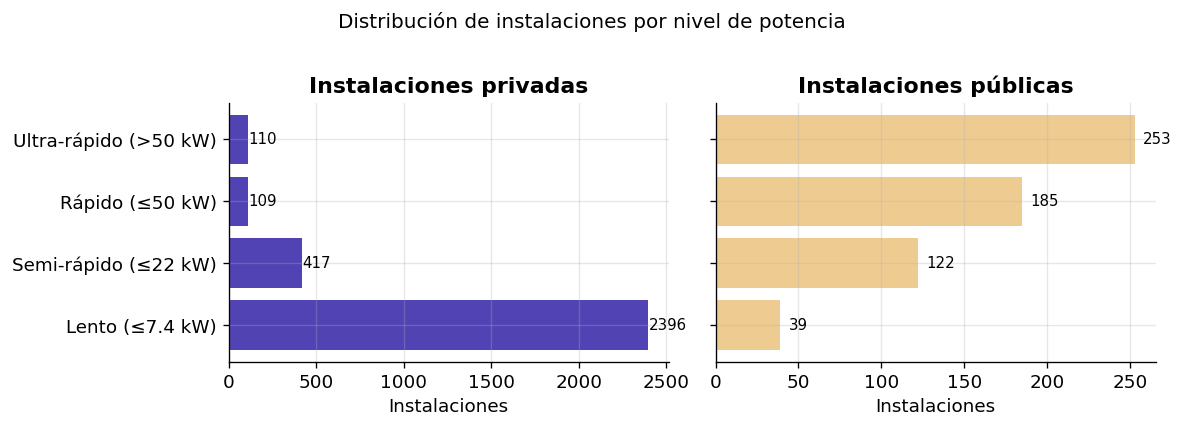


Conclusión: la potencia existe y tiene variabilidad → Tarea 1 FACTIBLE


In [4]:
# Clasificación de nivel de carga según kW
def nivel_carga(kw):
    if kw <= 7.4:
        return "Lento (≤7.4 kW)"
    elif kw <= 22:
        return "Semi-rápido (≤22 kW)"
    elif kw <= 50:
        return "Rápido (≤50 kW)"
    else:
        return "Ultra-rápido (>50 kW)"

orden_nivel = ["Lento (≤7.4 kW)", "Semi-rápido (≤22 kW)", "Rápido (≤50 kW)", "Ultra-rápido (>50 kW)"]

priv["NIVEL"] = priv["POTENCIA_ELECTROMOVILIDAD"].apply(nivel_carga)
pub["NIVEL"]  = pub["POTENCIA_ELECTROMOVILIDAD"].apply(nivel_carga)

# Contar por nivel
cnt_priv = priv["NIVEL"].value_counts().reindex(orden_nivel, fill_value=0)
cnt_pub  = pub["NIVEL"].value_counts().reindex(orden_nivel, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)

for ax, cnt, titulo, color in zip(
    axes,
    [cnt_priv, cnt_pub],
    ["Instalaciones privadas", "Instalaciones públicas"],
    [AZUL, MAGENTA]
):
    ax.barh(cnt.index, cnt.values, color=color, alpha=0.85)
    ax.set_xlabel("Instalaciones")
    ax.set_title(titulo, fontweight="bold")
    for i, v in enumerate(cnt.values):
        ax.text(v + 5, i, str(v), va="center", fontsize=9)

fig.suptitle("Distribución de instalaciones por nivel de potencia", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

print("\nConclusión: la potencia existe y tiene variabilidad → Tarea 1 FACTIBLE")

### 1d. Distribución de cargadores por instalación

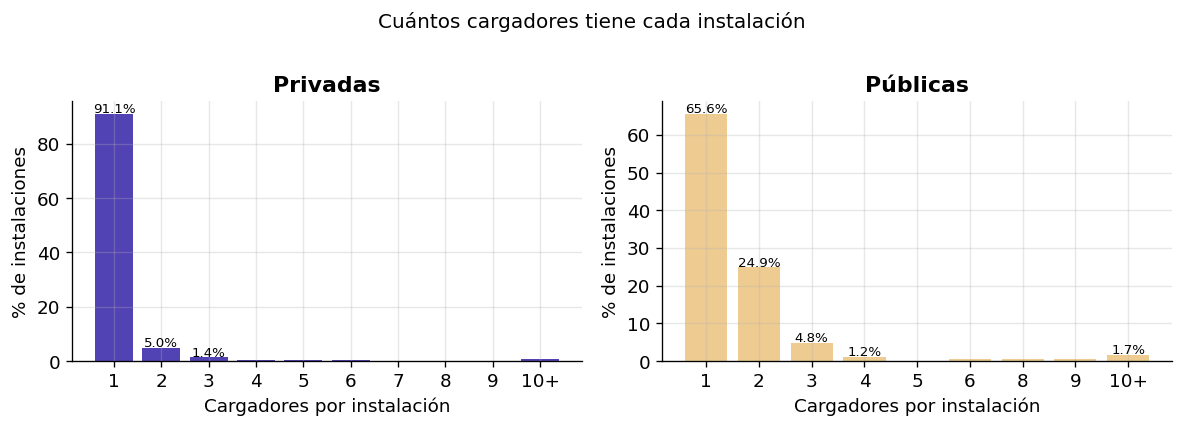

La mayoría de instalaciones privadas tiene 1 cargador; las públicas tienen mayor variabilidad.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

for ax, df, titulo, color in zip(
    axes,
    [priv, pub],
    ["Privadas", "Públicas"],
    [AZUL, MAGENTA]
):
    # Agrupar valores grandes en "10+"
    vals = df["CANTIDAD_CARGADORES"].clip(upper=10)
    cnt  = vals.value_counts().sort_index()
    etiq = [str(int(v)) if v < 10 else "10+" for v in cnt.index]
    pct  = 100 * cnt / cnt.sum()
    bars = ax.bar(etiq, pct.values, color=color, alpha=0.85)
    ax.set_xlabel("Cargadores por instalación")
    ax.set_ylabel("% de instalaciones")
    ax.set_title(titulo, fontweight="bold")
    for bar, p in zip(bars, pct.values):
        if p > 1:
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                    f"{p:.1f}%", ha="center", fontsize=8)

fig.suptitle("Cuántos cargadores tiene cada instalación", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

print("La mayoría de instalaciones privadas tiene 1 cargador; las públicas tienen mayor variabilidad.")

### 1e. Crecimiento temporal de la red

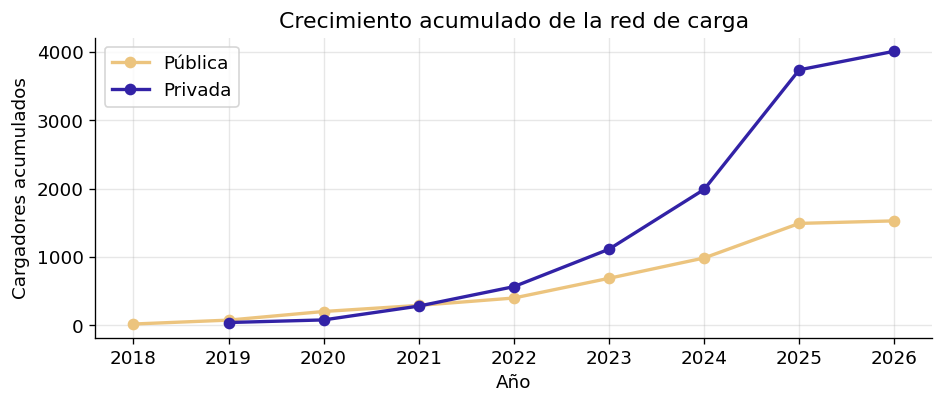

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))

for df, label, color in [(pub, "Pública", MAGENTA), (priv, "Privada", AZUL)]:
    por_año = df.groupby("AÑO")["CANTIDAD_CARGADORES"].sum().sort_index()
    acum    = por_año.cumsum()
    ax.plot(acum.index, acum.values, marker="o", label=label, color=color, lw=2)

ax.set_xlabel("Año")
ax.set_ylabel("Cargadores acumulados")
ax.set_title("Crecimiento acumulado de la red de carga")
ax.legend()
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

---
## Tarea 2 — Explorar la distribución espacial de la infraestructura

**Factibilidad:** Solo las instalaciones **públicas** incluyen coordenadas (LATITUD/LONGITUD) sin valores faltantes. Las privadas no las tienen — esto es una limitación que se debe declarar.

### 2a. Diagnóstico de coordenadas

In [7]:
print("Columnas con coordenadas en PÚBLICAS:")
print(pub[["LATITUD","LONGITUD"]].isnull().sum())
print(f"\nRango latitud  : {pub['LATITUD'].min():.4f}  a  {pub['LATITUD'].max():.4f}")
print(f"Rango longitud : {pub['LONGITUD'].min():.4f}  a  {pub['LONGITUD'].max():.4f}")
print(f"\nInstalaciones privadas con coordenadas: {'LATITUD' in priv.columns}")
print("\n⚠️  LIMITACIÓN: El análisis espacial se restringe a instalaciones públicas ({} registros).".format(len(pub)))

Columnas con coordenadas en PÚBLICAS:
LATITUD     0
LONGITUD    0
dtype: int64

Rango latitud  : -53.1661  a  -18.4628
Rango longitud : -73.8292  a  -68.1915

Instalaciones privadas con coordenadas: False

⚠️  LIMITACIÓN: El análisis espacial se restringe a instalaciones públicas (599 registros).


### 2b. Distribución por región

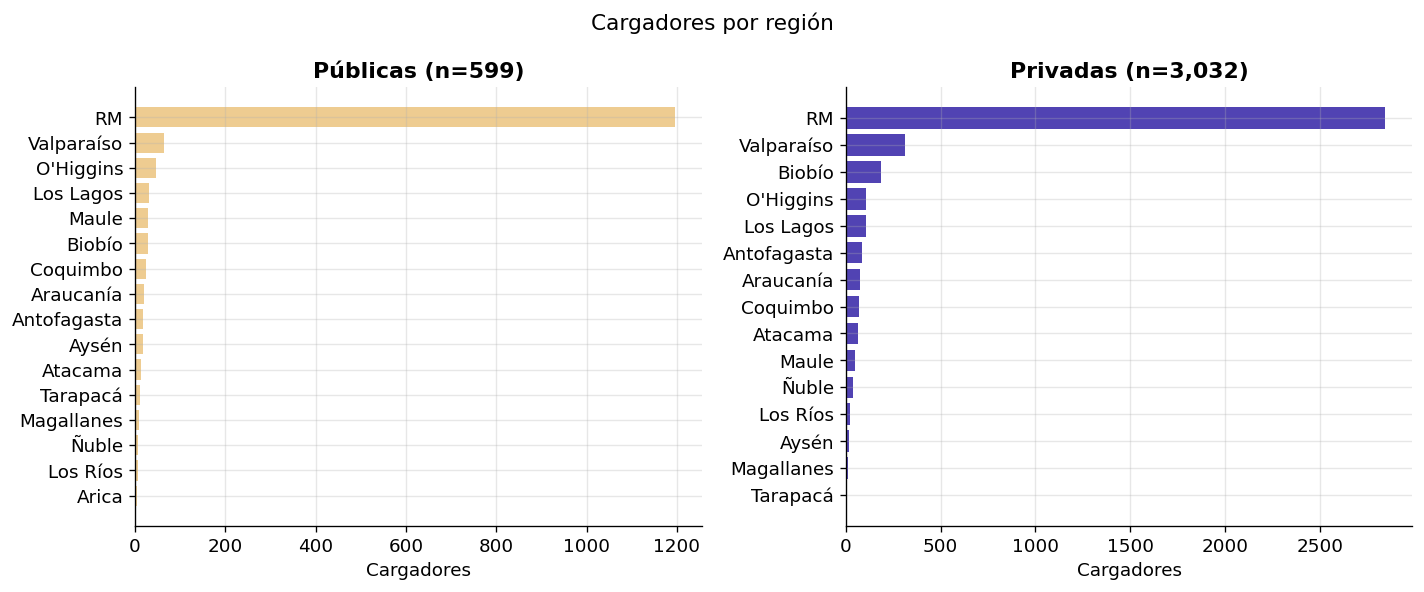

In [8]:
# Nombre corto de región para el eje
nombre_corto = {
    "Metropolitana": "RM",
    "Valparaíso": "Valparaíso",
    "Biobío": "Biobío",
    "Maule": "Maule",
    "La Araucanía": "Araucanía",
    "Los Lagos": "Los Lagos",
    "Libertador Bernardo OHiggins": "O'Higgins",
    "Ñuble": "Ñuble",
    "De los Ríos": "Los Ríos",
    "Coquimbo": "Coquimbo",
    "Antofagasta": "Antofagasta",
    "Atacama": "Atacama",
    "Aisén del General Carlos Ibáñez del Campo": "Aysén",
    "Magallanes y de la Antartica Chilena": "Magallanes",
    "Tarapacá": "Tarapacá",
    "Arica y Parinacota": "Arica",
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, df, titulo, color in zip(
    axes,
    [pub, priv],
    ["Públicas (n={:,})".format(len(pub)), "Privadas (n={:,})".format(len(priv))],
    [MAGENTA, AZUL]
):
    cnt = (df.groupby("REGION_INSTALACION")["CANTIDAD_CARGADORES"]
             .sum()
             .rename(index=nombre_corto)
             .sort_values(ascending=True))
    ax.barh(cnt.index, cnt.values, color=color, alpha=0.85)
    ax.set_xlabel("Cargadores")
    ax.set_title(titulo, fontweight="bold")

fig.suptitle("Cargadores por región", fontsize=13)
plt.tight_layout()
plt.show()

### 2c. Mapa de dispersión de instalaciones públicas (lat/lon)

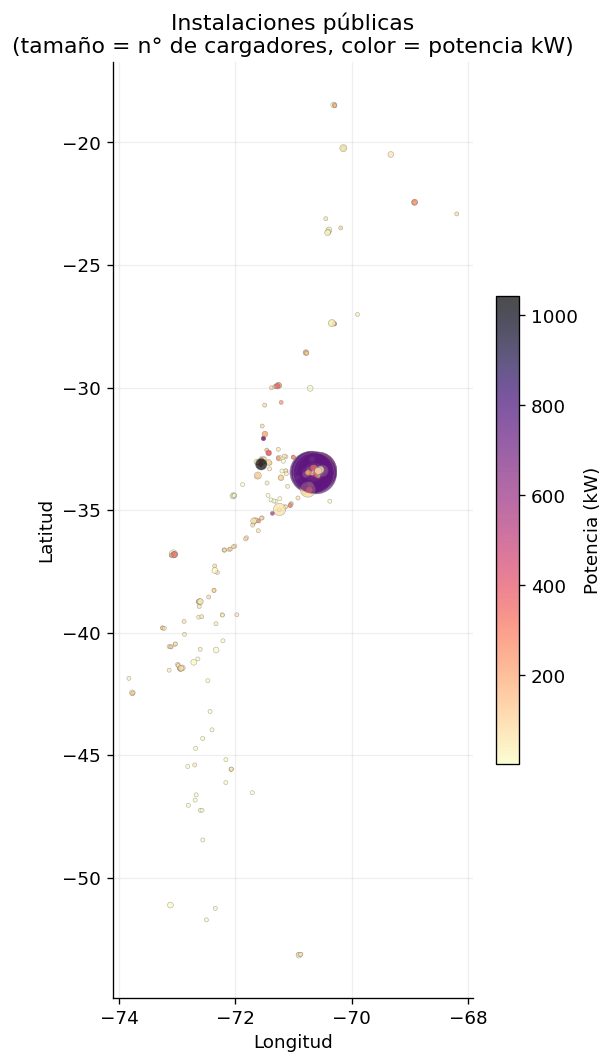


Conclusión: cobertura nacional con concentración en zona central → Tarea 2 FACTIBLE con datos públicos.


In [9]:
fig, ax = plt.subplots(figsize=(5, 9))

sc = ax.scatter(
    pub["LONGITUD"], pub["LATITUD"],
    c=pub["POTENCIA_ELECTROMOVILIDAD"],
    cmap="magma_r",
    s=pub["CANTIDAD_CARGADORES"] * 6,
    alpha=0.7,
    linewidths=0.3,
    edgecolors="gray"
)
plt.colorbar(sc, ax=ax, label="Potencia (kW)", shrink=0.5)
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Instalaciones públicas\n(tamaño = n° de cargadores, color = potencia kW)")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("\nConclusión: cobertura nacional con concentración en zona central → Tarea 2 FACTIBLE con datos públicos.")

### 2d. Concentración en la Región Metropolitana

Instalaciones públicas en RM: 358 (59.8% del total)


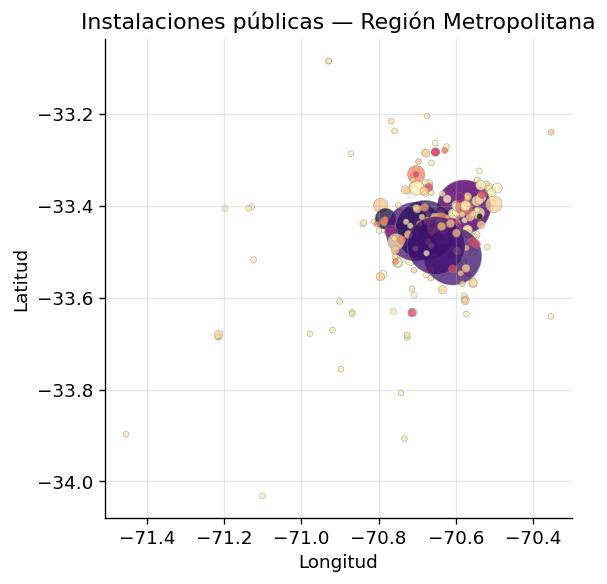

In [10]:
rm = pub[pub["REGION_INSTALACION"] == "Metropolitana"].copy()
print(f"Instalaciones públicas en RM: {len(rm)} ({100*len(rm)/len(pub):.1f}% del total)")

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(
    rm["LONGITUD"], rm["LATITUD"],
    c=rm["POTENCIA_ELECTROMOVILIDAD"],
    cmap="magma_r",
    s=rm["CANTIDAD_CARGADORES"] * 12,
    alpha=0.75,
    edgecolors="gray", linewidths=0.3
)
ax.set_title("Instalaciones públicas — Región Metropolitana")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
plt.tight_layout()
plt.show()

Instalaciones públicas en RM: 358 (59.8% del total)


c:\Users\Lenovo\infovis\InfoVis\.venv\lib\site-packages\geopandas\array.py:334: UserWarning: Cannot set the CRS, falling back to None. The CRS support requires the 'pyproj' package, but it is not installed or does not import correctly. The functions depending on CRS will raise an error or may produce unexpected results.
  self.crs = crs
c:\Users\Lenovo\infovis\InfoVis\.venv\lib\site-packages\geopandas\geodataframe.py:409: UserWarning: Cannot set the CRS, falling back to None. The CRS support requires the 'pyproj' package, but it is not installed or does not import correctly. The functions depending on CRS will raise an error or may produce unexpected results.
  level.crs = crs


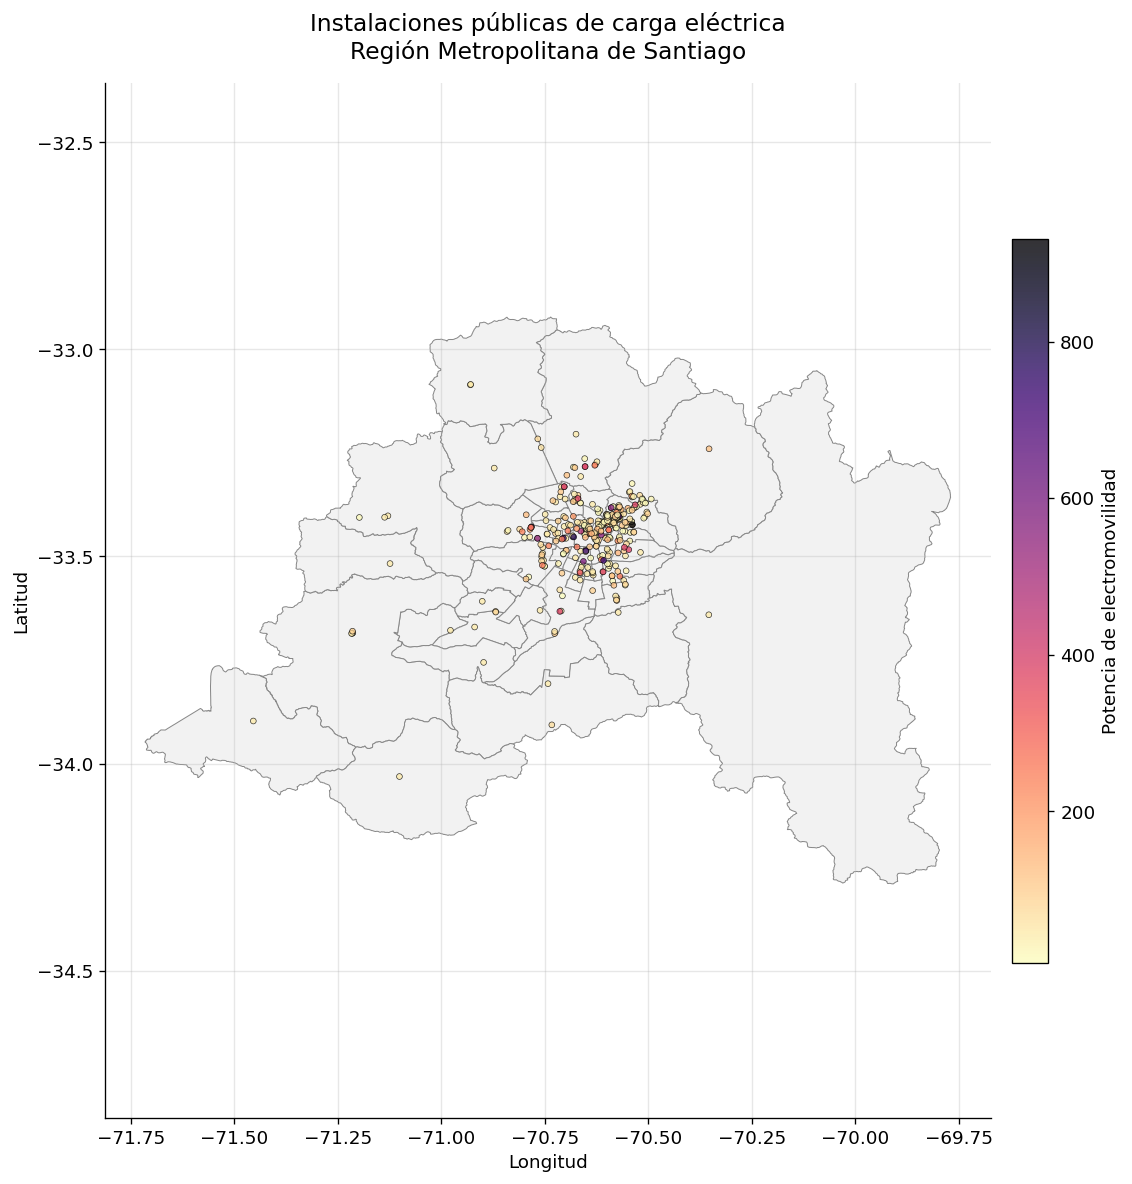

In [28]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

# 1. Filtrar instalaciones públicas de la Región Metropolitana
rm = pub[pub["REGION_INSTALACION"] == "Metropolitana"].copy()

print(
    f"Instalaciones públicas en RM: {len(rm)} "
    f"({100 * len(rm) / len(pub):.1f}% del total)"
)

# 2. Descargar los límites geográficos de las comunas de la RM
url_mapa = (
    "https://services.arcgis.com/JZxvGBwvCaXCwa4l/"
    "ArcGIS/rest/services/Comunas_Regi%C3%B3n_Metropolitana/"
    "FeatureServer/0/query"
    "?where=1%3D1&outFields=*&outSR=4326&f=geojson"
)

mapa_rm = gpd.read_file(url_mapa)

# 3. Crear la visualización
fig, ax = plt.subplots(figsize=(10, 10))

# Dibujar las comunas como fondo
mapa_rm.plot(
    ax=ax,
    facecolor="#F2F2F2",
    edgecolor="#888888",
    linewidth=0.6,
    zorder=1
)

# 4. Superponer las instalaciones públicas
puntos = ax.scatter(
    rm["LONGITUD"],
    rm["LATITUD"],
    c=rm["POTENCIA_ELECTROMOVILIDAD"],
    cmap="magma_r",
    s=12,
    alpha=0.8,
    edgecolors="black",
    linewidths=0.4,
    zorder=2
)

# 5. Configurar títulos, ejes y leyenda
cbar = plt.colorbar(puntos, ax=ax, shrink=0.7, pad=0.02)
cbar.set_label("Potencia de electromovilidad")

ax.set_title(
    "Instalaciones públicas de carga eléctrica\n"
    "Región Metropolitana de Santiago",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_aspect("equal", adjustable="datalim")

plt.tight_layout()
plt.show()

---
## Tarea 3 — Analizar la separación entre puntos de carga

**Factibilidad:** Con coordenadas de las instalaciones públicas se puede calcular la distancia al vecino más cercano. Se usa distancia haversine (sobre esfera) para obtener km reales.

### 3a. Función de distancia haversine

In [11]:
def haversine_km(lat1, lon1, lat2, lon2):
    """Distancia en km entre dos puntos (grados decimales)."""
    R = 6371.0
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi  = np.radians(lat2 - lat1)
    dlam  = np.radians(lon2 - lon1)
    a = np.sin(dphi/2)**2 + np.cos(phi1)*np.cos(phi2)*np.sin(dlam/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

# Verificación rápida: Santiago → Valparaíso ≈ 100 km
d_test = haversine_km(-33.45, -70.65, -33.05, -71.61)
print(f"Santiago → Valparaíso : {d_test:.1f} km  (referencia ≈ 100 km)")

Santiago → Valparaíso : 99.7 km  (referencia ≈ 100 km)


### 3b. Distancia al vecino más cercano (NN) entre instalaciones públicas

In [12]:
coords_rad = np.radians(pub[["LATITUD", "LONGITUD"]].values)

# cKDTree en coordenadas cartesianas proyectadas (aproximación esférica)
# Para mayor precisión usamos conversión a xyz en la esfera unitaria
def latlon_to_xyz(lat_rad, lon_rad):
    x = np.cos(lat_rad) * np.cos(lon_rad)
    y = np.cos(lat_rad) * np.sin(lon_rad)
    z = np.sin(lat_rad)
    return np.column_stack([x, y, z])

xyz = latlon_to_xyz(coords_rad[:, 0], coords_rad[:, 1])
tree = cKDTree(xyz)

# k=2: el primer resultado es la propia instalación (distancia 0)
dists_chord, _ = tree.query(xyz, k=2)
dist_chord_nn  = dists_chord[:, 1]  # distancia al vecino más cercano

# Convertir distancia de cuerda a km: d_km = 2 * R * arcsin(chord/2)
R = 6371.0
dist_km_nn = 2 * R * np.arcsin(dist_chord_nn / 2)

pub["DIST_NN_KM"] = dist_km_nn

print("Distancia al vecino más cercano (km):")
print(pd.Series(dist_km_nn).describe().round(2))

Distancia al vecino más cercano (km):
count    599.00
mean       4.41
std       12.81
min        0.00
25%        0.20
50%        0.58
75%        1.58
max      134.65
dtype: float64


### 3c. Distribución de la separación entre instalaciones

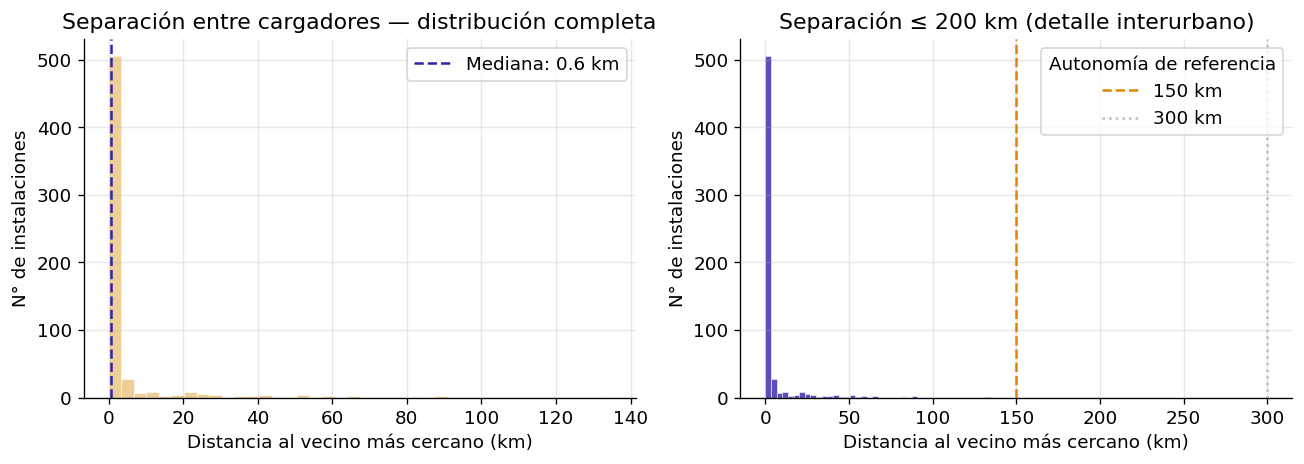

Instalaciones con NN > 150 km: 0 (0.0%)
Instalaciones con NN > 300 km: 0 (0.0%)

Conclusión: la separación tiene variabilidad relevante → Tarea 3 FACTIBLE.


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Histograma completo
ax = axes[0]
ax.hist(dist_km_nn, bins=40, color=MAGENTA, alpha=0.8, edgecolor="white", linewidth=0.4)
ax.set_xlabel("Distancia al vecino más cercano (km)")
ax.set_ylabel("N° de instalaciones")
ax.set_title("Separación entre cargadores — distribución completa")
ax.axvline(np.median(dist_km_nn), color=AZUL, lw=1.5, linestyle="--", label=f"Mediana: {np.median(dist_km_nn):.1f} km")
ax.legend()

# Zoom en zona ≤ 200 km (interurbano relevante)
ax = axes[1]
mask = dist_km_nn <= 200
ax.hist(dist_km_nn[mask], bins=40, color=AZUL, alpha=0.8, edgecolor="white", linewidth=0.4)
ax.set_xlabel("Distancia al vecino más cercano (km)")
ax.set_ylabel("N° de instalaciones")
ax.set_title("Separación ≤ 200 km (detalle interurbano)")
# Líneas de referencia de autonomía
for autonomia, color_ref, ls in [(150, NARANJA, "--"), (300, GRIS, ":")]:
    ax.axvline(autonomia, color=color_ref, lw=1.5, linestyle=ls, label=f"{autonomia} km")
ax.legend(title="Autonomía de referencia")

plt.tight_layout()
plt.show()

print(f"Instalaciones con NN > 150 km: {(dist_km_nn > 150).sum()} ({100*(dist_km_nn > 150).mean():.1f}%)")
print(f"Instalaciones con NN > 300 km: {(dist_km_nn > 300).sum()} ({100*(dist_km_nn > 300).mean():.1f}%)")
print("\nConclusión: la separación tiene variabilidad relevante → Tarea 3 FACTIBLE.")

### 3d. Separación por región

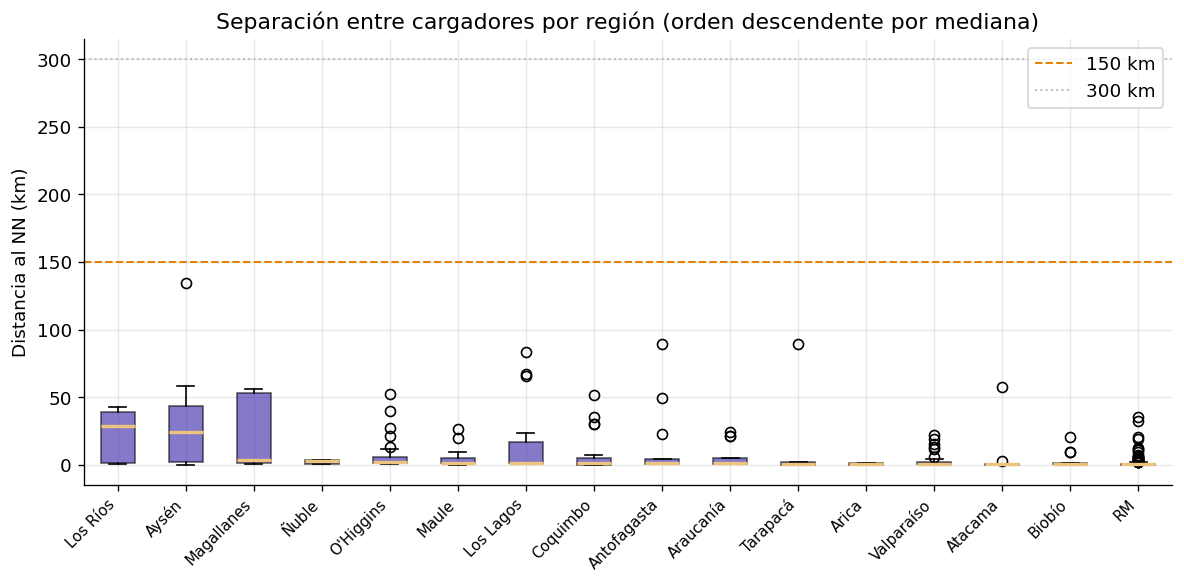

In [14]:
pub["REGION_CORTA"] = pub["REGION_INSTALACION"].map(nombre_corto).fillna(pub["REGION_INSTALACION"])

orden_mediana = (pub.groupby("REGION_CORTA")["DIST_NN_KM"]
                    .median()
                    .sort_values(ascending=False)
                    .index)

fig, ax = plt.subplots(figsize=(10, 5))
data_box = [pub.loc[pub["REGION_CORTA"] == r, "DIST_NN_KM"].values for r in orden_mediana]
bp = ax.boxplot(data_box, vert=True, patch_artist=True,
                medianprops=dict(color=MAGENTA, linewidth=2))
for patch in bp["boxes"]:
    patch.set_facecolor(AZUL)
    patch.set_alpha(0.6)

ax.set_xticks(range(1, len(orden_mediana)+1))
ax.set_xticklabels(orden_mediana, rotation=45, ha="right", fontsize=9)
ax.set_ylabel("Distancia al NN (km)")
ax.set_title("Separación entre cargadores por región (orden descendente por mediana)")
ax.axhline(150, color=NARANJA, lw=1.2, ls="--", label="150 km")
ax.axhline(300, color=GRIS,   lw=1.2, ls=":",  label="300 km")
ax.legend()
plt.tight_layout()
plt.show()

---
## Tarea 4 — Comparar separaciones con distintos rangos de autonomía

**Factibilidad:** Con las distancias calculadas en Tarea 3, se puede clasificar cada tramo como accesible o no para distintos rangos de autonomía.

### 4a. Rangos de autonomía representativos

In [15]:
# Vehículos eléctricos de referencia (autonomía WLTP aproximada)
autonomias = {
    "Urbano (150 km)": 150,
    "Compacto (250 km)": 250,
    "Estándar (350 km)": 350,
    "Premium (500 km)": 500,
}

# Para cada autonomía: ¿qué fracción de instalaciones tiene su NN dentro del rango?
# Se asume que el vehículo puede recorrer hasta 80% de la autonomía antes de recargar
factores_uso = [0.5, 0.6, 0.7, 0.8]  # fracción de autonomía antes de recargar

print("Fracción de instalaciones con vecino más cercano ACCESIBLE por autonomía y factor de uso\n")
header = "Autonomía          " + "  ".join(f"  {int(f*100)}%" for f in factores_uso)
print(header)
print("-" * len(header))

tabla_acceso = {}
for label, km in autonomias.items():
    row = []
    for f in factores_uso:
        umbral = km * f
        frac   = (dist_km_nn <= umbral).mean()
        row.append(frac)
    tabla_acceso[label] = row
    fila = f"{label:<22}" + "   ".join(f"{v:.1%}" for v in row)
    print(fila)

Fracción de instalaciones con vecino más cercano ACCESIBLE por autonomía y factor de uso

Autonomía            50%    60%    70%    80%
---------------------------------------------
Urbano (150 km)       99.3%   99.8%   99.8%   99.8%
Compacto (250 km)     99.8%   100.0%   100.0%   100.0%
Estándar (350 km)     100.0%   100.0%   100.0%   100.0%
Premium (500 km)      100.0%   100.0%   100.0%   100.0%


### 4b. Visualización: accesibilidad por autonomía y factor de uso

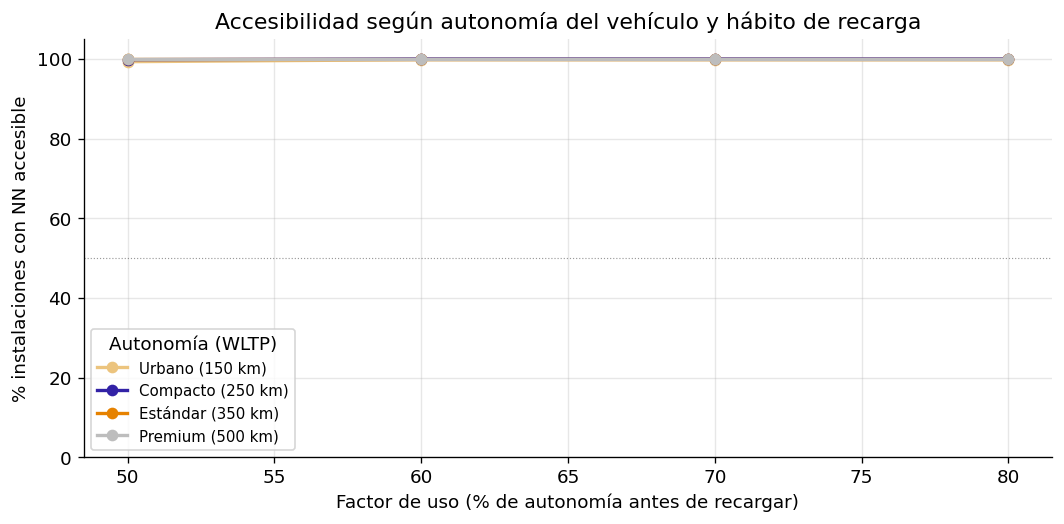


Conclusión: se puede comparar accesibilidad para distintos perfiles de VE → Tarea 4 FACTIBLE.


In [16]:
fig, ax = plt.subplots(figsize=(9, 4.5))

colores_linea = [MAGENTA, AZUL, NARANJA, GRIS]

for (label, row), color in zip(tabla_acceso.items(), colores_linea):
    ax.plot([f * 100 for f in factores_uso], [v * 100 for v in row],
            marker="o", lw=2, color=color, label=label)

ax.set_xlabel("Factor de uso (% de autonomía antes de recargar)")
ax.set_ylabel("% instalaciones con NN accesible")
ax.set_title("Accesibilidad según autonomía del vehículo y hábito de recarga")
ax.legend(title="Autonomía (WLTP)", fontsize=9)
ax.set_ylim(0, 105)
ax.axhline(50, color="black", lw=0.7, ls=":", alpha=0.4)
plt.tight_layout()
plt.show()

print("\nConclusión: se puede comparar accesibilidad para distintos perfiles de VE → Tarea 4 FACTIBLE.")

### 4c. Mapa de accesibilidad: instalaciones con NN > umbral

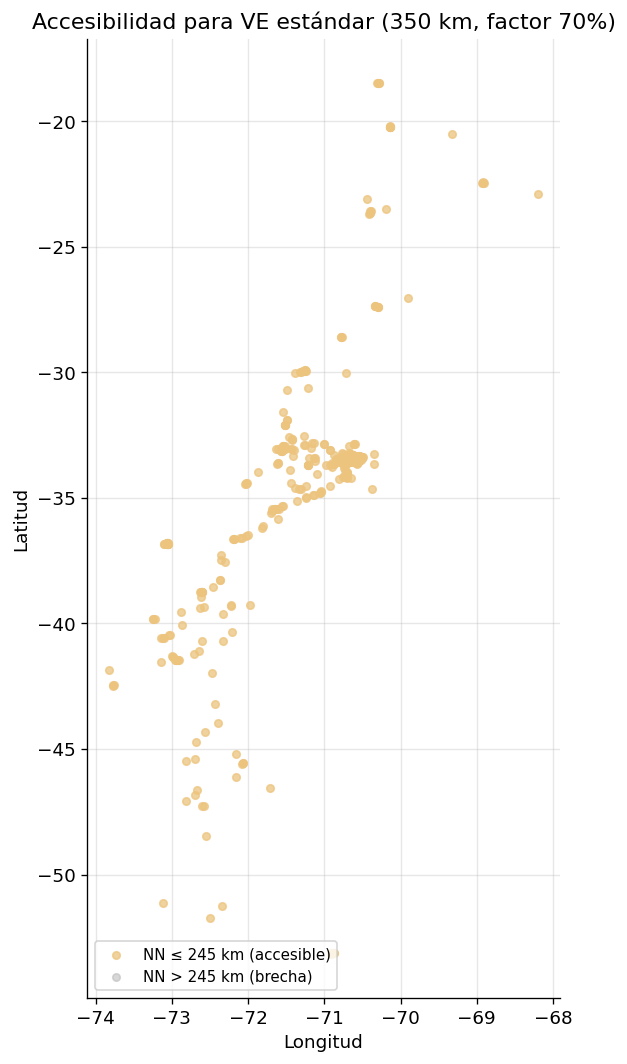

In [17]:
# Para autonomía estándar (350 km) con factor 70% → umbral = 245 km
AUTONOMIA_REF = 350
FACTOR_REF    = 0.70
UMBRAL        = AUTONOMIA_REF * FACTOR_REF

accesible     = pub["DIST_NN_KM"] <= UMBRAL

fig, ax = plt.subplots(figsize=(5, 9))

ax.scatter(
    pub.loc[accesible, "LONGITUD"],
    pub.loc[accesible, "LATITUD"],
    color=MAGENTA, alpha=0.75, s=20, label=f"NN ≤ {UMBRAL:.0f} km (accesible)",
    zorder=3
)
ax.scatter(
    pub.loc[~accesible, "LONGITUD"],
    pub.loc[~accesible, "LATITUD"],
    color=GRIS, alpha=0.6, s=20, label=f"NN > {UMBRAL:.0f} km (brecha)",
    zorder=2
)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title(f"Accesibilidad para VE estándar ({AUTONOMIA_REF} km, factor {int(FACTOR_REF*100)}%)")
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

---
## Resumen de factibilidad

In [18]:
resumen_factibilidad = pd.DataFrame({
    "Tarea": [
        "1. Caracterizar cantidad y capacidad",
        "2. Distribución espacial",
        "3. Separación entre puntos de carga",
        "4. Comparar con rangos de autonomía",
    ],
    "Variables usadas": [
        "CANTIDAD_CARGADORES, POTENCIA_ELECTROMOVILIDAD",
        "LATITUD, LONGITUD (solo públicas)",
        "LATITUD, LONGITUD → distancia haversine NN",
        "DIST_NN_KM + umbrales de autonomía definidos",
    ],
    "Valores faltantes": ["0 / 3631", "0 / 599", "0 / 599", "N/A (derivada)"],
    "Factible": ["✅ Sí", "✅ Sí (con limitación)", "✅ Sí", "✅ Sí"],
    "Limitación": [
        "Privadas sin coordenadas, solo cantidad/potencia",
        "Privadas sin lat/lon: solo distribución por región/comuna",
        "Basado únicamente en instalaciones públicas",
        "Autonomías son WLTP estimadas, no mediciones reales",
    ]
})

print(resumen_factibilidad.to_string(index=False))

                               Tarea                               Variables usadas Valores faltantes              Factible                                                Limitación
1. Caracterizar cantidad y capacidad CANTIDAD_CARGADORES, POTENCIA_ELECTROMOVILIDAD          0 / 3631                  ✅ Sí          Privadas sin coordenadas, solo cantidad/potencia
            2. Distribución espacial              LATITUD, LONGITUD (solo públicas)           0 / 599 ✅ Sí (con limitación) Privadas sin lat/lon: solo distribución por región/comuna
 3. Separación entre puntos de carga     LATITUD, LONGITUD → distancia haversine NN           0 / 599                  ✅ Sí               Basado únicamente en instalaciones públicas
 4. Comparar con rangos de autonomía   DIST_NN_KM + umbrales de autonomía definidos    N/A (derivada)                  ✅ Sí       Autonomías son WLTP estimadas, no mediciones reales



# Hito 2 — Preparación del proyecto

## 1. Propuesta actualizada

**Título del proyecto:** Accesibilidad territorial de la infraestructura de carga para vehículos eléctricos en Chile.

**Problema:** La distribución de los puntos de carga puede generar diferencias en las posibilidades de desplazamiento de los usuarios de vehículos eléctricos, especialmente en sectores donde la distancia entre instalaciones es elevada.

**Objetivo:** Explorar la distribución, capacidad y separación geográfica de la infraestructura de carga pública y privada, evaluando cómo cambia la accesibilidad potencial según distintos rangos de autonomía de vehículos eléctricos.

**Preguntas de análisis:**
1. ¿Cómo se distribuyen las instalaciones según su tipo, cantidad de cargadores y potencia?
2. ¿Cómo varía la distribución territorial de los cargadores públicos entre regiones?
3. ¿Qué regiones presentan mayores distancias entre instalaciones públicas cercanas?
4. ¿Qué proporción de las instalaciones tiene otra instalación a una distancia compatible con distintos rangos de autonomía?

**Unidad de análisis:** Instalación de carga. Para el análisis territorial se utilizan las instalaciones públicas, debido a que son las que disponen de coordenadas geográficas en los datos disponibles.

**Alcance:** El análisis permite estudiar la distribución espacial y la accesibilidad potencial a partir de distancias geográficas. No mide directamente la disponibilidad operativa de los cargadores, los tiempos de espera ni las rutas reales de conducción.

In [19]:

# ============================================================
# HITO 2 — 2. ANÁLISIS EXPLORATORIO GENERAL
# ============================================================

print("=" * 65)
print("RESUMEN GENERAL DE LA INFRAESTRUCTURA DE CARGA")
print("=" * 65)

total_instalaciones = len(priv) + len(pub)
total_cargadores_priv = priv["CANTIDAD_CARGADORES"].sum()
total_cargadores_pub = pub["CANTIDAD_CARGADORES"].sum()

resumen_general = pd.DataFrame({
    "Indicador": [
        "Instalaciones privadas",
        "Instalaciones públicas",
        "Total de instalaciones",
        "Cargadores en instalaciones privadas",
        "Cargadores en instalaciones públicas",
        "Potencia media privada (kW)",
        "Potencia media pública (kW)",
        "Regiones con instalaciones públicas",
        "Instalaciones públicas con coordenadas"
    ],
    "Valor": [
        len(priv),
        len(pub),
        total_instalaciones,
        total_cargadores_priv,
        total_cargadores_pub,
        priv["POTENCIA_ELECTROMOVILIDAD"].mean(),
        pub["POTENCIA_ELECTROMOVILIDAD"].mean(),
        pub["REGION_INSTALACION"].nunique(),
        pub[["LATITUD", "LONGITUD"]].dropna().shape[0]
    ]
})

display(resumen_general.round(2))

# Comparación de potencia y cantidad de cargadores por tipo
comparacion_tipo = pd.concat({
    "Privadas": priv[
        ["CANTIDAD_CARGADORES", "POTENCIA_ELECTROMOVILIDAD"]
    ].describe(),
    "Públicas": pub[
        ["CANTIDAD_CARGADORES", "POTENCIA_ELECTROMOVILIDAD"]
    ].describe()
}, axis=1)

print("\nEstadísticos descriptivos por tipo de instalación:")
display(comparacion_tipo.round(2))

RESUMEN GENERAL DE LA INFRAESTRUCTURA DE CARGA


,Indicador,Valor
0,Instalaciones privadas,3032.00
1,Instalaciones públicas,599.00
2,Total de instalaciones,3631.00
3,Cargadores en instalaciones privadas,4006.00
4,Cargadores en instalaciones públicas,1528.00
5,Potencia media privada (kW),13.99
6,Potencia media pública (kW),89.40
7,Regiones con instalaciones públicas,16.00
8,Instalaciones públicas con coordenadas,599.00



Estadísticos descriptivos por tipo de instalación:


Privadas                                      Públicas  \
      CANTIDAD_CARGADORES POTENCIA_ELECTROMOVILIDAD CANTIDAD_CARGADORES   
count             3032.00                   3032.00              599.00   
mean                 1.32                     13.99                2.55   
std                  2.30                     41.16                9.62   
min                  1.00                      0.00                1.00   
25%                  1.00                      7.00                1.00   
50%                  1.00                      7.40                1.00   
75%                  1.00                      7.40                2.00   
max                 64.00                    811.30              106.00   

                                 
      POTENCIA_ELECTROMOVILIDAD  
count                    599.00  
mean                      89.40  
std                      131.39  
min                        2.80  
25%                       22.00  
50%                       44.00  
75%                       94.46  
max                     1042.80

Comparación regional de instalaciones públicas (umbral de referencia: 245 km)


,instalaciones,cargadores,potencia_media_kw,distancia_mediana_km,distancia_promedio_km,distancia_maxima_km,pct_sobre_umbral
REGION_CORTA,,,,,,,
Los Ríos,7,7,61.75,29.01,22.00,42.76,0.0
Aysén,17,17,20.08,23.99,30.88,134.65,0.0
Magallanes,7,9,45.12,3.85,24.28,55.77,0.0
Ñuble,7,7,82.61,2.72,2.09,3.78,0.0
O'Higgins,27,46,67.03,1.96,7.76,52.25,0.0
Maule,20,30,120.67,1.65,4.69,26.75,0.0
Los Lagos,25,32,52.69,1.58,13.50,83.52,0.0
Coquimbo,19,24,163.34,1.19,8.69,51.92,0.0
Antofagasta,13,19,71.78,1.15,13.51,89.18,0.0


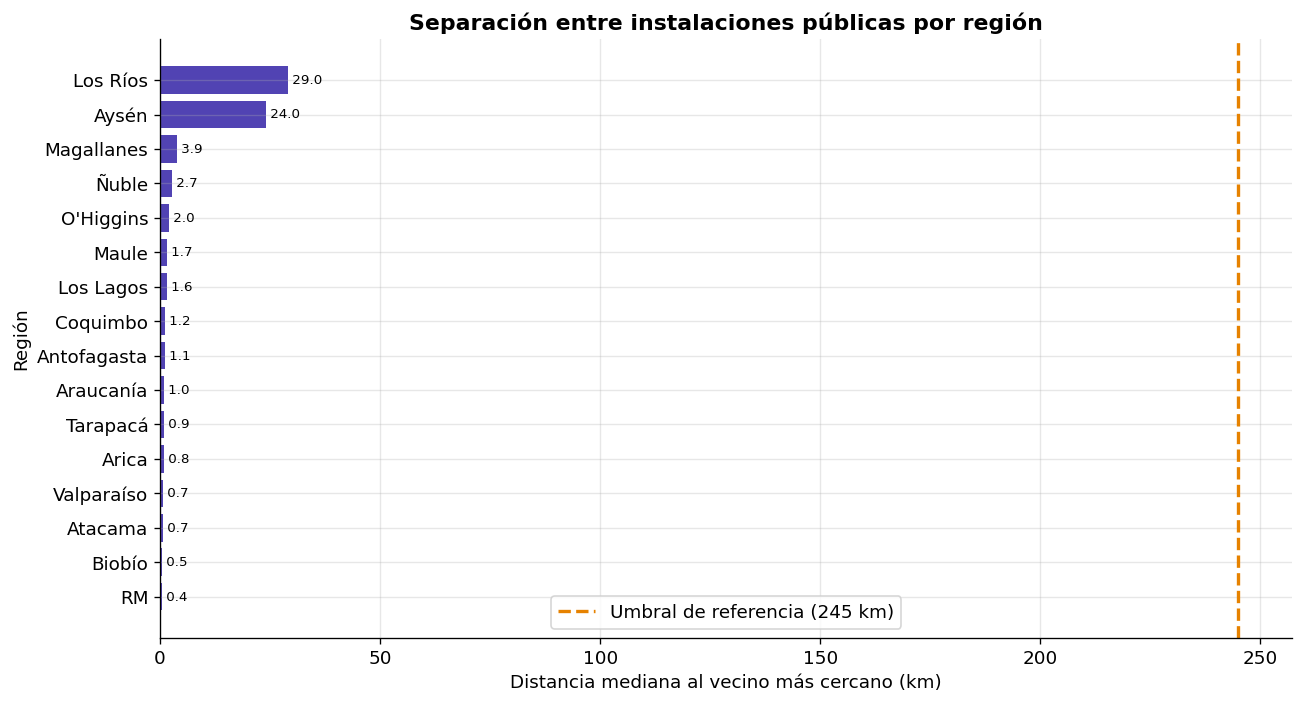

In [20]:

# ============================================================
# HITO 2 — 3. ANÁLISIS POR SUBGRUPOS TERRITORIALES
# ============================================================

# Umbral de referencia:
# vehículo de autonomía de 350 km, usando el 70% antes de recargar.
AUTONOMIA_REF = 350
FACTOR_REF = 0.70
UMBRAL_REF = AUTONOMIA_REF * FACTOR_REF

# Asegurar que existe la clasificación abreviada de regiones
pub["REGION_CORTA"] = (
    pub["REGION_INSTALACION"]
    .map(nombre_corto)
    .fillna(pub["REGION_INSTALACION"])
)

# Resumen por región de las instalaciones públicas
resumen_regional = (
    pub.groupby("REGION_CORTA")
    .agg(
        instalaciones=("DIST_NN_KM", "size"),
        cargadores=("CANTIDAD_CARGADORES", "sum"),
        potencia_media_kw=("POTENCIA_ELECTROMOVILIDAD", "mean"),
        distancia_mediana_km=("DIST_NN_KM", "median"),
        distancia_promedio_km=("DIST_NN_KM", "mean"),
        distancia_maxima_km=("DIST_NN_KM", "max"),
        pct_sobre_umbral=(
            "DIST_NN_KM",
            lambda x: 100 * (x > UMBRAL_REF).mean()
        )
    )
    .sort_values("distancia_mediana_km", ascending=False)
)

print(
    f"Comparación regional de instalaciones públicas "
    f"(umbral de referencia: {UMBRAL_REF:.0f} km)"
)
display(resumen_regional.round(2))

# Gráfico: distancia mediana al vecino más cercano por región
fig, ax = plt.subplots(figsize=(11, 6))

datos_grafico = resumen_regional.sort_values(
    "distancia_mediana_km", ascending=True
)

barras = ax.barh(
    datos_grafico.index,
    datos_grafico["distancia_mediana_km"],
    color=AZUL,
    alpha=0.85
)

ax.axvline(
    UMBRAL_REF,
    color=NARANJA,
    linestyle="--",
    linewidth=2,
    label=f"Umbral de referencia ({UMBRAL_REF:.0f} km)"
)

ax.set_xlabel("Distancia mediana al vecino más cercano (km)")
ax.set_ylabel("Región")
ax.set_title(
    "Separación entre instalaciones públicas por región",
    fontweight="bold"
)
ax.legend()

for barra in barras:
    ancho = barra.get_width()
    ax.text(
        ancho,
        barra.get_y() + barra.get_height() / 2,
        f" {ancho:.1f}",
        va="center",
        fontsize=8
    )

plt.tight_layout()
plt.show()

Porcentaje de instalaciones cuyo vecino más cercano está dentro del umbral de distancia para un vehículo de 350 km:


,Autonomía utilizable 50%,Autonomía utilizable 70%,Autonomía utilizable 80%
Region,,,
Antofagasta,100.0,100.0,100.0
Araucanía,100.0,100.0,100.0
Arica,100.0,100.0,100.0
Atacama,100.0,100.0,100.0
Aysén,100.0,100.0,100.0
Biobío,100.0,100.0,100.0
Coquimbo,100.0,100.0,100.0
Los Lagos,100.0,100.0,100.0
Los Ríos,100.0,100.0,100.0


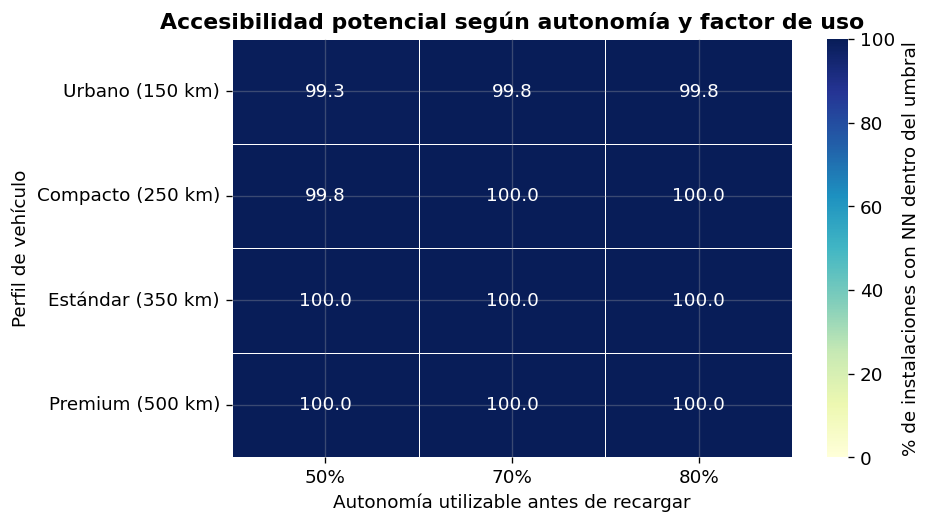

In [21]:

# ============================================================
# HITO 2 — 4. ACCESIBILIDAD POTENCIAL POR REGIÓN Y AUTONOMÍA
# ============================================================

# Usar los rangos de autonomía que ya están definidos en el notebook.
# El factor de uso representa la proporción de autonomía que se
# considera disponible antes de necesitar una recarga.

factores_region = [0.5, 0.7, 0.8]
filas_accesibilidad = []

for region, grupo in pub.groupby("REGION_CORTA"):
    distancias = grupo["DIST_NN_KM"].dropna()

    for nombre_vehiculo, autonomia_km in autonomias.items():
        for factor in factores_region:
            umbral = autonomia_km * factor

            filas_accesibilidad.append({
                "Region": region,
                "Vehiculo": nombre_vehiculo,
                "Autonomia_km": autonomia_km,
                "Factor_uso": factor,
                "Umbral_km": umbral,
                "Instalaciones": len(distancias),
                "Porcentaje_con_NN_accesible": (
                    100 * (distancias <= umbral).mean()
                    if len(distancias) > 0 else np.nan
                )
            })

accesibilidad_regional = pd.DataFrame(filas_accesibilidad)

# Tabla resumida para un vehículo de autonomía estándar de 350 km
tabla_350 = accesibilidad_regional[
    accesibilidad_regional["Autonomia_km"] == 350
].pivot(
    index="Region",
    columns="Factor_uso",
    values="Porcentaje_con_NN_accesible"
)

tabla_350.columns = [
    f"Autonomía utilizable {int(f * 100)}%"
    for f in tabla_350.columns
]

print(
    "Porcentaje de instalaciones cuyo vecino más cercano "
    "está dentro del umbral de distancia para un vehículo de 350 km:"
)
display(tabla_350.round(1))

# Mapa de calor de las cuatro autonomías y tres factores de uso,
# agregando todas las instalaciones públicas.
tabla_calor = pd.DataFrame(
    index=autonomias.keys(),
    columns=[f"{int(f * 100)}%" for f in factores_region],
    dtype=float
)

for nombre_vehiculo, autonomia_km in autonomias.items():
    for factor in factores_region:
        umbral = autonomia_km * factor
        tabla_calor.loc[nombre_vehiculo, f"{int(factor * 100)}%"] = (
            100 * (pub["DIST_NN_KM"] <= umbral).mean()
        )

fig, ax = plt.subplots(figsize=(8, 4.5))

sns.heatmap(
    tabla_calor.astype(float),
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "% de instalaciones con NN dentro del umbral"},
    ax=ax
)

ax.set_title(
    "Accesibilidad potencial según autonomía y factor de uso",
    fontweight="bold"
)
ax.set_xlabel("Autonomía utilizable antes de recargar")
ax.set_ylabel("Perfil de vehículo")

plt.tight_layout()
plt.show()


## 7. Conclusiones del Hito 2 y visualizaciones propuestas

### Conclusiones del análisis exploratorio

El análisis permite caracterizar la infraestructura de carga según su tipo, cantidad de cargadores y potencia, además de estudiar su distribución geográfica a partir de las instalaciones públicas que cuentan con coordenadas.

El cálculo de la distancia al vecino más cercano permite comparar la separación entre instalaciones y observar diferencias territoriales. La evaluación de distintos rangos de autonomía permite estimar qué proporción de instalaciones tiene otra instalación a una distancia compatible con los umbrales considerados.

Estos resultados permiten describir patrones espaciales y formular preguntas sobre posibles brechas de cobertura. Sin embargo, las distancias geográficas deben interpretarse como indicadores de accesibilidad potencial y no como medidas directas de cobertura vial o disponibilidad efectiva.

### Visualizaciones propuestas para el siguiente hito

1. **Visualización global:** mapa de Chile con la ubicación de las instalaciones públicas, utilizando símbolos cuyo tamaño represente la cantidad de cargadores y cuyo color represente la potencia.

2. **Visualización comparativa:** gráfico de barras por región que permita comparar la cantidad de cargadores y la cantidad de instalaciones públicas.

4. **Visualización de accesibilidad potencial:** mapa que distinga instalaciones cuyo vecino más cercano se encuentra dentro o fuera de un umbral definido según la autonomía del vehículo.

5. **Visualización focalizada:** matriz de calor que compare los porcentajes de instalaciones con un vecino dentro del umbral para distintos rangos de autonomía y factores de uso


## Insight esperado y próximos pasos

### ¿Dónde buscaremos el insight?

Se estudiará el cruce entre la región, la distancia al vecino más cercano y el porcentaje de instalaciones públicas que tienen otra instalación dentro del umbral de distancia definido para cada perfil de autonomía.

La comparación permitirá examinar si las diferencias regionales observadas en la separación entre instalaciones se mantienen al considerar distintas autonomías de vehículos eléctricos.

### ¿Por qué es relevante?

Una misma distancia puede representar una exigencia diferente para vehículos con distintas autonomías. Examinar ambas variables conjuntamente permite describir la accesibilidad geográfica potencial sin asumir que la cercanía entre instalaciones garantiza cobertura efectiva.

### ¿Qué visualizaremos en el Hito 3?

- Un mapa de la distribución de instalaciones públicas.
- Un gráfico comparativo de distancias al vecino más cercano por región.
- Una matriz de calor que compare regiones, autonomía y factor de uso.

La selección final de las visualizaciones dependerá de los patrones que efectivamente se observen en el análisis exploratorio.